<a href="https://colab.research.google.com/github/trishulip/YES-BANK-Stock-Price-Prediction/blob/main/notebooks/YES_BANK_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load YES BANK stock dataset

df = pd.read_csv("data_YesBank_StockPrices.csv")

# Display first five records
df.head()


,Date,Open,High,Low,Close
0,Jul-05,13.00,14.00,11.25,12.46
1,Aug-05,12.58,14.88,12.55,13.42
2,Sep-05,13.48,14.87,12.27,13.30
3,Oct-05,13.20,14.47,12.40,12.99
4,Nov-05,13.35,13.88,12.88,13.41


In [3]:

# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset information:")
df.info()

# Check statistical summary
print("\nStatistical summary:")
display(df.describe())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())


Number of rows: 185
Number of columns: 5

Column names:
['Date', 'Open', 'High', 'Low', 'Close']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    185 non-null    object 
 1   Open    185 non-null    float64
 2   High    185 non-null    float64
 3   Low     185 non-null    float64
 4   Close   185 non-null    float64
dtypes: float64(4), object(1)
memory usage: 7.4+ KB

Statistical summary:


,Open,High,Low,Close
count,185.000000,185.000000,185.000000,185.000000
mean,105.541405,116.104324,94.947838,105.204703
std,98.879850,106.333497,91.219415,98.583153
min,10.000000,11.240000,5.550000,9.980000
25%,33.800000,36.140000,28.510000,33.450000
50%,62.980000,72.550000,58.000000,62.540000
75%,153.000000,169.190000,138.350000,153.300000
max,369.950000,404.000000,345.500000,367.900000



Missing values:
Date     0
Open     0
High     0
Low      0
Close    0
dtype: int64


In [4]:

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'], format='%b-%y')

# Sort records chronologically
df = df.sort_values('Date').reset_index(drop=True)

# Verify the conversion
print(df.dtypes)

# Display first five records
df.head()


Date     datetime64[ns]
Open            float64
High            float64
Low             float64
Close           float64
dtype: object


,Date,Open,High,Low,Close
0,2005-07-01,13.00,14.00,11.25,12.46
1,2005-08-01,12.58,14.88,12.55,13.42
2,2005-09-01,13.48,14.87,12.27,13.30
3,2005-10-01,13.20,14.47,12.40,12.99
4,2005-11-01,13.35,13.88,12.88,13.41


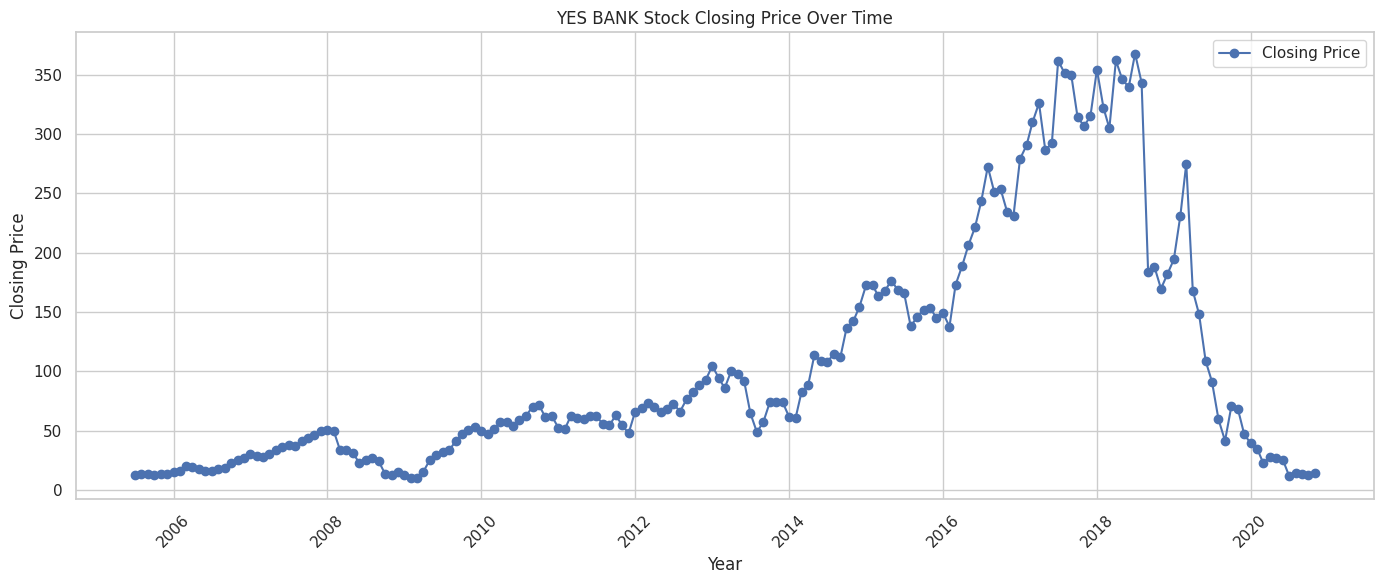

In [5]:

plt.figure(figsize=(14, 6))

plt.plot(df['Date'], df['Close'], marker='o',
         linewidth=1.5, label='Closing Price')

plt.title('YES BANK Stock Closing Price Over Time')
plt.xlabel('Year')
plt.ylabel('Closing Price')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


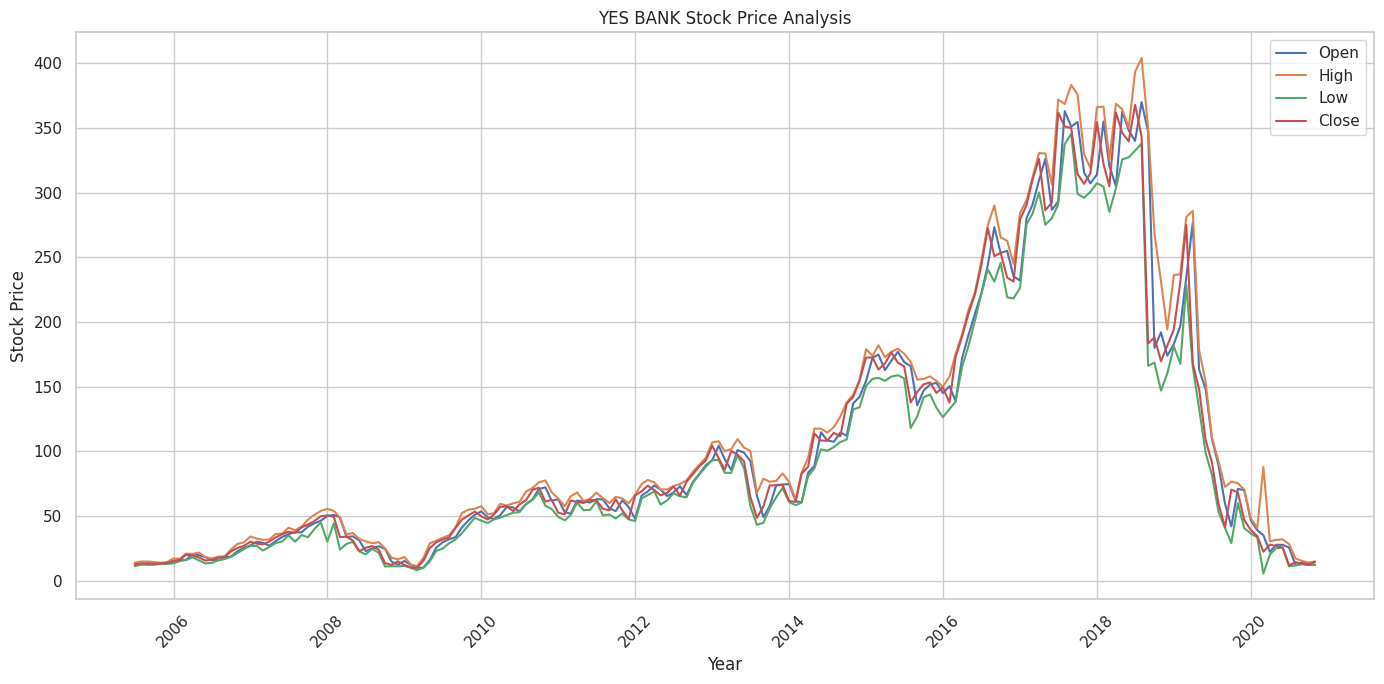

In [6]:

# Visualize all YES BANK stock price variables

plt.figure(figsize=(14, 7))

plt.plot(df['Date'], df['Open'], label='Open')
plt.plot(df['Date'], df['High'], label='High')
plt.plot(df['Date'], df['Low'], label='Low')
plt.plot(df['Date'], df['Close'], label='Close')

plt.title('YES BANK Stock Price Analysis')
plt.xlabel('Year')
plt.ylabel('Stock Price')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


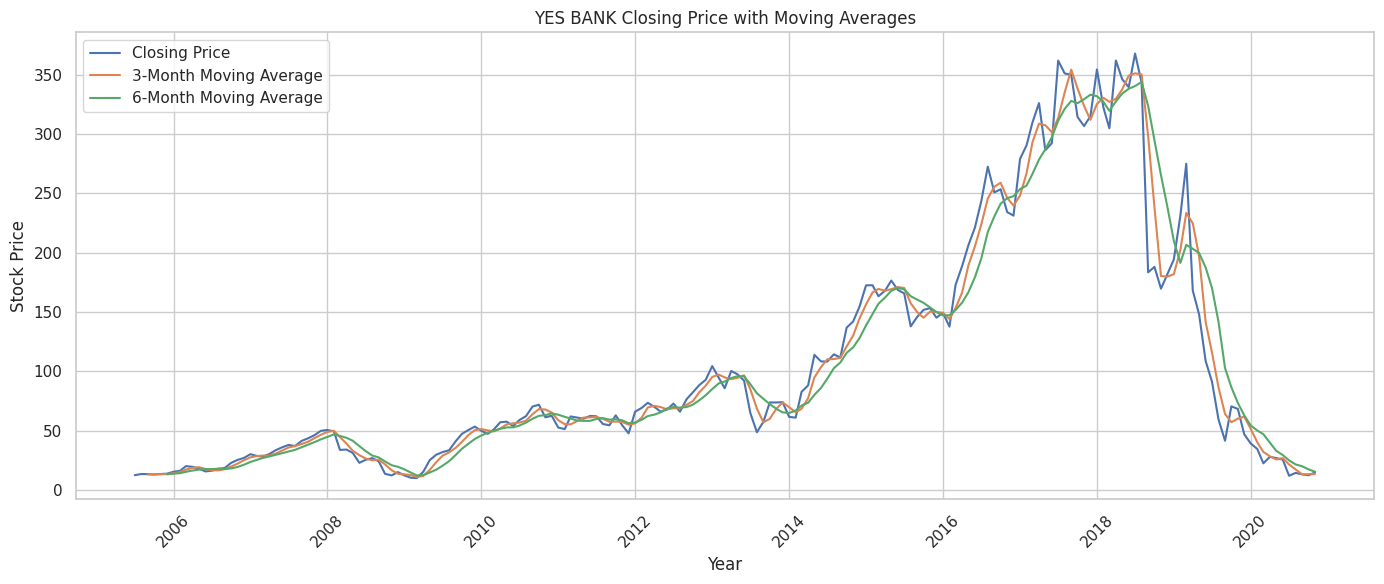

In [7]:

# Calculate 3-month and 6-month moving averages

df['MA_3'] = df['Close'].rolling(window=3).mean()
df['MA_6'] = df['Close'].rolling(window=6).mean()

# Plot closing price and moving averages

plt.figure(figsize=(14, 6))

plt.plot(df['Date'], df['Close'], label='Closing Price')
plt.plot(df['Date'], df['MA_3'], label='3-Month Moving Average')
plt.plot(df['Date'], df['MA_6'], label='6-Month Moving Average')

plt.title('YES BANK Closing Price with Moving Averages')
plt.xlabel('Year')
plt.ylabel('Stock Price')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Correlation Matrix:


,Open,High,Low,Close
Open,1.000000,0.993040,0.983978,0.977971
High,0.993040,1.000000,0.983422,0.985051
Low,0.983978,0.983422,1.000000,0.995358
Close,0.977971,0.985051,0.995358,1.000000


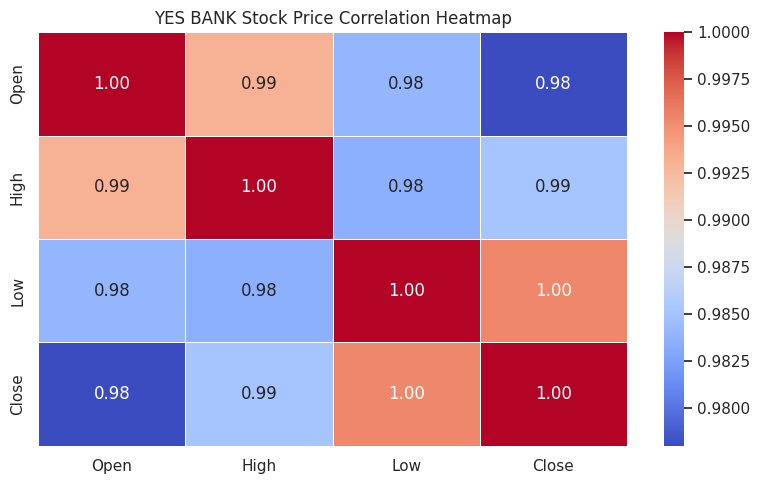

In [8]:

# Calculate correlation between stock price variables

correlation = df[['Open', 'High', 'Low', 'Close']].corr()

print("Correlation Matrix:")
display(correlation)

# Create correlation heatmap

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('YES BANK Stock Price Correlation Heatmap')
plt.tight_layout()
plt.show()


In [9]:

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check dataset shape
print("\nDataset Shape:", df.shape)



Missing Values:
Date     0
Open     0
High     0
Low      0
Close    0
MA_3     2
MA_6     5
dtype: int64

Duplicate Records:
0

Dataset Shape: (185, 7)


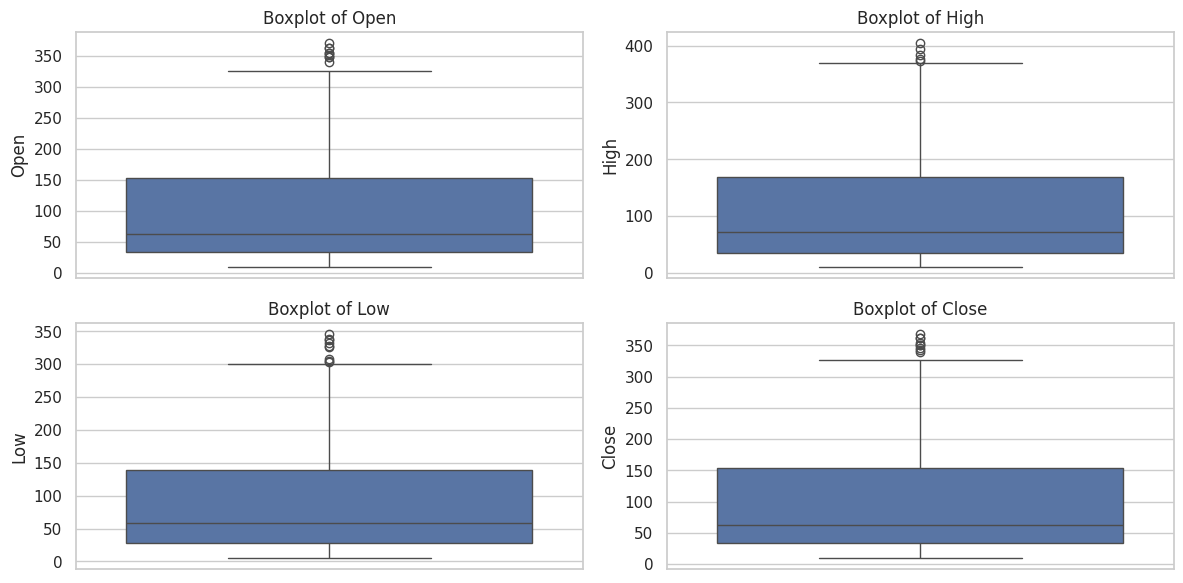

In [10]:

# Visualize outliers using boxplots

plt.figure(figsize=(12, 6))

for i, column in enumerate(['Open', 'High', 'Low', 'Close']):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(y=df[column])
    plt.title(f'Boxplot of {column}')

plt.tight_layout()
plt.show()


In [11]:

# Calculate outliers using the IQR method

for column in ['Open', 'High', 'Low', 'Close']:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f"\n{column}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))



Open
Lower Limit: -145.0
Upper Limit: 331.8
Number of Outliers: 9

High
Lower Limit: -163.435
Upper Limit: 368.765
Number of Outliers: 5

Low
Lower Limit: -136.25
Upper Limit: 303.11
Number of Outliers: 9

Close
Lower Limit: -146.325
Upper Limit: 333.07500000000005
Number of Outliers: 9


In [12]:

# Feature Engineering

# Extract year and month
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

# Calculate monthly price range
df['Price_Range'] = df['High'] - df['Low']

# Calculate monthly percentage return
df['Monthly_Return'] = df['Close'].pct_change() * 100

# Display newly created features
display(df.head(10))

print("Feature engineering completed!")


,Date,Open,High,Low,Close,MA_3,MA_6,Year,Month,Price_Range,Monthly_Return
0,2005-07-01,13.00,14.00,11.25,12.46,NaN,NaN,2005,7,2.75,NaN
1,2005-08-01,12.58,14.88,12.55,13.42,NaN,NaN,2005,8,2.33,7.704655
2,2005-09-01,13.48,14.87,12.27,13.30,13.060000,NaN,2005,9,2.60,-0.894188
3,2005-10-01,13.20,14.47,12.40,12.99,13.236667,NaN,2005,10,2.07,-2.330827
4,2005-11-01,13.35,13.88,12.88,13.41,13.233333,NaN,2005,11,1.00,3.233256
5,2005-12-01,13.49,14.44,13.00,13.71,13.370000,13.215000,2005,12,1.44,2.237136
6,2006-01-01,13.68,17.16,13.58,15.33,14.150000,13.693333,2006,1,3.58,11.816193
7,2006-02-01,15.50,16.97,15.40,16.12,15.053333,14.143333,2006,2,1.57,5.153294
8,2006-03-01,16.20,20.95,16.02,20.08,17.176667,15.273333,2006,3,4.93,24.565757
9,2006-04-01,20.56,20.80,18.02,19.49,18.563333,16.356667,2006,4,2.78,-2.938247


Feature engineering completed!


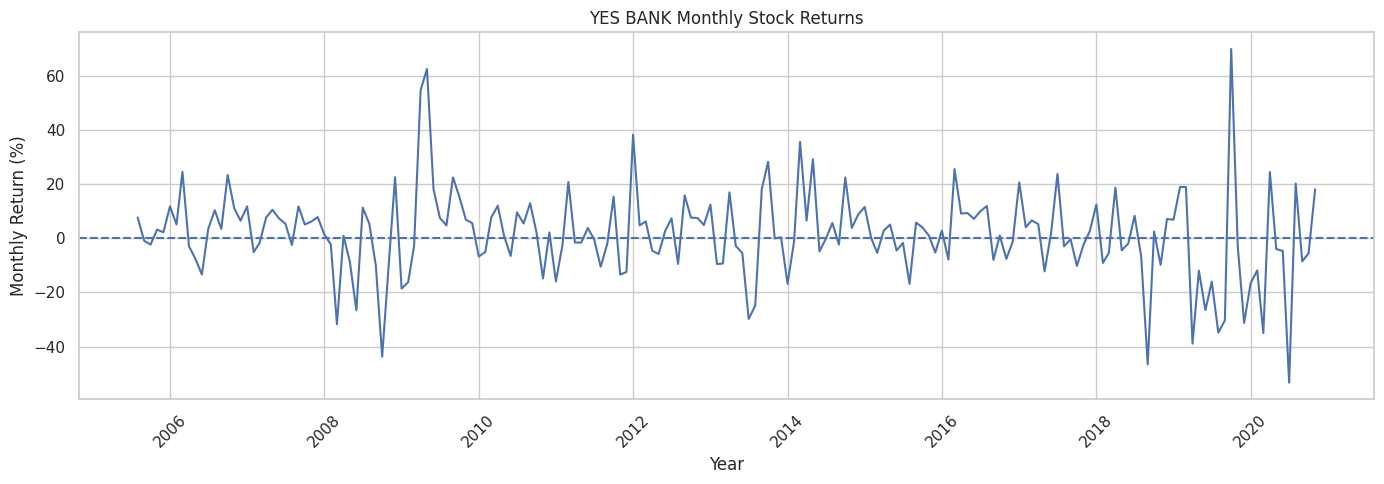

In [13]:

plt.figure(figsize=(14, 5))

plt.plot(df['Date'], df['Monthly_Return'])

plt.axhline(y=0, linestyle='--')

plt.title('YES BANK Monthly Stock Returns')
plt.xlabel('Year')
plt.ylabel('Monthly Return (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


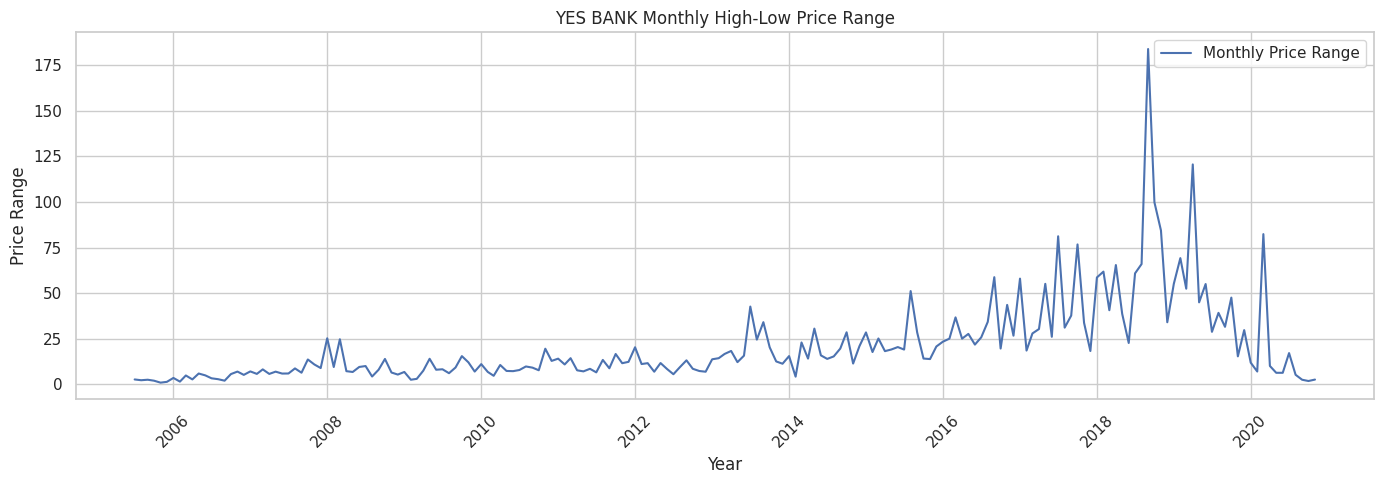

In [14]:

plt.figure(figsize=(14, 5))

plt.plot(df['Date'], df['Price_Range'],
         label='Monthly Price Range')

plt.title('YES BANK Monthly High-Low Price Range')
plt.xlabel('Year')
plt.ylabel('Price Range')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:

# Save the processed dataset

df.to_csv('YES_BANK_EDA_Processed.csv', index=False)

print("Processed dataset saved successfully!")


Processed dataset saved successfully!
